# Application of QMCCBO: A two-dimensional data-driven model for traffic flow in highways

### Data Set: Vehicle Trajectory Dataset from Drone Videos by Moritz Berghausa, Serge Lambertya, Jörg Ehlersa, Eszter Kallóa, Markus Oeser

### Sensitivity Analysis

# Off-ramp data set

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle, ConnectionPatch

df = pd.read_csv("data/DroneDataWestToEastCSV_220725.csv")

C:\Users\jheieck\AppData\Local\Temp\ipykernel_5432\1462137398.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
# transform velocity [m/s] to [km/h]
df["vx_kmh"] = df["vx"] * 3.6  
df["vy_kmh"] = df["vy"] * 3.6 

# determine density
L = df["x"].max() - df["x"].min()  # road length [m]
df["t_bin"] = np.floor(df["tseconds"])
N = df.groupby("t_bin")["ID"].nunique()
rho = N / (L / 1000)  # \tilde{rho}(t_k): density [vehicle/km] per time 

# determine average velocity and fluxes
ux_kmh = df.groupby("t_bin")["vx_kmh"].mean()  # \tilde{u}^x(t_k): average velocity [km/h] in x-direction per time 
uy_kmh = df.groupby("t_bin")["vy_kmh"].mean()  # \tilde{u}^y(t_k): aberage velocity [km/h] in y-direction per time
qx = rho * ux_kmh  # \tilde{q}^x(t_k): flux [vehicle/h] in x-direction per time 
qy = rho * uy_kmh  # \tilde{q}^y(t_k): flux [vehicle/h] in x-direction per time 

# determine moving mean of densitiy, flux and average velocity
window_value = 60*3  # corresponds to 180 seconds
rho_data = rho.rolling(window=window_value, min_periods=window_value).mean()
qx_data = qx.rolling(window=window_value, min_periods=window_value).mean()
qy_data = qy.rolling(window=window_value, min_periods=window_value).mean()

# neglect non-numerical values
mask = (rho_data.notna() & qx_data.notna() & qy_data.notna())  
rho_data = rho_data[mask]
qx_data = qx_data[mask]
qy_data = qy_data[mask]
ux_data = qx_data / rho_data 
uy_data = qy_data / rho_data

# transform to torch-tensor for (QMC)CBO application
rho_torch = torch.tensor(rho_data.to_numpy(), dtype=torch.float32)
qx_torch = torch.tensor(qx_data.to_numpy(), dtype=torch.float32)
qy_torch = torch.tensor(qy_data.to_numpy(), dtype=torch.float32)
ux_torch = qx_torch / rho_torch
uy_torch = qy_torch / rho_torch

### Model and objective functions

In [3]:
number_lanes = 2  # number of lanes without off-ramp
rho_max = number_lanes / 7.5 * 1000  # maxmial density [vehicle/km]

# Model functions 

# Scipy optimization
# INPUT: - alpha (scalar): alpha parameter
#        - lam (scalar): lambda parameter
#        - p (scalar): p parameter
#        - rho (1xM numpy-vector): density rho for any obersvation (data point)
# OUTPUT: - prediction (1xM numpy-vector): approximated flux for model parameter combination and observed data point (column)
def qx_model_numpy(rho, alpha, lam, p):

    d1 = np.sqrt(1 + (lam*p)**2)
    d2 = np.sqrt(1 + (lam*(1-p))**2)
    d3 = lam*(rho/rho_max - p)
    return alpha*(d1 + (d2-d1)*(rho/rho_max) - np.sqrt(1 + d3**2))

def qy_model_numpy(rho, alpha, lam, p):

    d1 = np.sqrt(1 + (lam*p)**2)
    d2 = np.sqrt(1 + (lam*(1-p))**2)
    d3 = lam*(rho/rho_max - p)
    return alpha*(d1 + (d2-d1)*(rho/rho_max) - np.sqrt(1 + d3**2))

# (QMC)CBO 
# INPUT: - alpha (Nx1 torch-tensor): alpha parameters for all particles
#        - lam (Nx1 torch-tensor): lambda parameters for all particles
#        - p (Nx1 torch-tensor): p parameters for all particles
#        - rho (1xM torch-tensor): density rho for any obersvation (data point)
# OUTPUT: - prediction (NxM torch-tensor): approximated flux for any model parameter combination (row) and observed data point (column)
def qx_model_torch(alpha, lam, p, rho):

    d1 = torch.sqrt(1 + (lam*p)**2)  # torch-tensor size Nx1
    d2 = torch.sqrt(1 + (lam*(1-p))**2)  # torch-tensor size Nx1
    d3 = lam*(rho/rho_max - p)  # broadcasting: Nx1 * (1xM/1x1 - Nx1) = NxM
    return alpha * (d1 + (d2-d1)*(rho/rho_max) - torch.sqrt(1 + d3**2))  # broadcasting: Nx1 * ( Nx1 + Nx1 * 1xM) - NxM )

def qy_model_torch(alpha, lam, p, rho):

    d1 = torch.sqrt(1 + (lam*p)**2)  # torch-tensor size Nx1
    d2 = torch.sqrt(1 + (lam*(1-p))**2)  # torch-tensor size Nx1
    d3 = lam*(rho/rho_max - p)  # broadcasting: Nx1 * (1xM/1x1 - Nx1) = NxM
    return alpha * (d1 + (d2-d1)*(rho/rho_max) - torch.sqrt(1 + d3**2))  # broadcasting: Nx1 * ( Nx1 + Nx1 * 1xM) - NxM )



# Objective functions

# Scipy optimization
# INPUT : - theta ((3) numpy-vector): describing three modelparameters
# OUTPUT : - scalar: describes the loss for theta model parameters
def objective_x_numpy(theta):
    alpha, lam, p = theta
    q_fit = qx_model_numpy(rho_data, alpha, lam, p)
    return np.sum((qx_data - q_fit)**2)

def objective_y_numpy(theta):
    alpha, lam, p = theta
    q_fit = qy_model_numpy(rho_data, alpha, lam, p)
    return np.sum((qy_data - q_fit)**2)

# (QMC)CBO
# INPUT : - V ((N x 3)-torch-matrix): describing three modelparameters for each particle/model parameter configuration
# OUTPUT : - V_prime ((1xN)-torch-matrix): describes the loss for each model parameter configuration
def objective_x_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qx = qx_torch[None, :]

    qx_prediction = qx_model_torch(alpha, lam, p, rho)
    return torch.sum((qx_prediction - qx)**2, dim=1)

def objective_y_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qy = qy_torch[None, :]

    qy_prediction = qy_model_torch(alpha, lam, p, rho)
    return torch.sum((qy_prediction - qy)**2, dim=1)

In [4]:
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
import optimization.CBO as CBO
import optimization.QMCCBO_base2 as QMCCBO_base2
from torch.distributions import Uniform
from IPython.display import display, Math
import time

# compute fitted data
rho_plot = np.linspace(rho_data.min(), rho_data.max(), 1000)

## Sensitivity of QMCCBO to system parameters

In [6]:
# set input for (QMC)CBO
dimensionality = 3  # dimension of the problem
n_particles = 11  # number of agents 2^n_particles
dt = 0.05  # step size of discretization
l = 1  # lambda (drift paramter)
sigma = 1
alpha = 100  # alpha (consensus weight)
n_particles_batches = 1  # batch size of each batch
epochs = 100  # number of iteration od SDE solution scheme (M)
batch_size = None
time_horizon = None

K = 500  # radius of cube
x_est = np.array([0,0,0])  # estimation of minimizer
ODE_method = 'Euler'  # SDE solution scheme 
theta = 0

In [7]:
alphas = [1, 10, 100, 1000]  # set of different alphas
particles_list = [7, 9, 11, 13]  # set of different number of particles

QMCCBO_sensitivity_results = []

# 
for alpha in alphas:
    for n_particles in particles_list:

        # Model prediction
        start_time = time.perf_counter()
        result_x = QMCCBO_base2.minimize(
            objective_x_torch, dimensionality, n_particles, K, x_est, dt, l, alpha,
            ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
            use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
            best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False,cooling=False)

        result_y = QMCCBO_base2.minimize(
            objective_y_torch, dimensionality, n_particles, K, x_est, dt, l, alpha,
            ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
            use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
            best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
        end_time = time.perf_counter()

        alpha_x, lambda_x, p_x = result_x.numpy()
        alpha_y, lambda_y, p_y = result_y.numpy()

        # errors
        qx_err = np.linalg.norm(qx_data - qx_model_numpy(rho_data, alpha_x, lambda_x, p_x)) / np.linalg.norm(qx_data)

        qy_err = np.linalg.norm(qy_data - qy_model_numpy(rho_data, alpha_y, lambda_y, p_y)) / np.linalg.norm(qy_data)

        QMCCBO_sensitivity_results.append({
            "alpha": alpha,
            "n_particles": n_particles,
            "err_x": qx_err,
            "err_y": qy_err,
            "time": end_time - start_time
        })

In [8]:
from IPython.display import display, HTML

df = pd.DataFrame(QMCCBO_sensitivity_results)
table_x = df.pivot(index="alpha", columns="n_particles", values="err_x")
table_y = df.pivot(index="alpha", columns="n_particles", values="err_y")
display(
    HTML(
        f"""
        <div style="display: flex; gap: 40px;">
            <div>
                <h4>error x-direction</h4>
                {table_x.to_html()}
            </div>
            <div>
                <h4>error y-direction</h4>
                {table_y.to_html()}
            </div>
        </div>
        """
    )
)

n_particles,7,9,11,13
alpha,,,,
1,0.99912,0.894014,0.06919,0.056982
10,0.99912,0.894014,0.06919,0.056982
100,0.99912,0.894014,0.06919,0.056982
1000,0.99912,0.894014,0.06919,0.056982
n_particles,7,9,11,13
alpha,,,,
1,0.278219,0.240428,0.238841,0.238400
10,0.278219,0.240428,0.239013,0.238543
100,0.278219,0.240428,0.239014,0.238543


In [9]:
table_time = df.pivot(index="alpha", columns="n_particles", values="time")
table_time

n_particles,7,9,11,13
alpha,,,,
1,0.591120,2.854271,11.619258,44.899295
10,0.529049,2.774985,10.987840,42.147624
100,0.296397,2.451665,10.632530,42.291677
1000,0.325999,2.421182,10.548092,42.143683


## Impact of starting configuration

### Comaprison QMCCBO with different starting configurations

In [7]:
initial_method = ['halton', 'halton_scramble', 'lattice']
# initial_method = ['sobol','sobol_scramble', 'halton', 'halton_scramble', 'lattice', 'uniform', 'normal']
QMCCBO_results = {}

# Model prediction and qualitiy measures for each starting point
for method in initial_method:

    # Model prediction
    result_x = QMCCBO_base2.minimize_different_starting(
        objective_x_torch, dimensionality, n_particles, K, x_est, dt, l, alpha, 
        ODE_method, theta, method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
    result_y = QMCCBO_base2.minimize_different_starting(
        objective_y_torch, dimensionality, n_particles, K, x_est, dt, l, alpha, 
        ODE_method, theta, method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
    alpha_x, lambda_x, p_x = result_x.numpy()
    alpha_y, lambda_y, p_y = result_y.numpy()

    # Fitted curves
    qx_fit = qx_model_numpy(rho_plot, alpha_x, lambda_x, p_x)
    qy_fit = qy_model_numpy(rho_plot, alpha_y, lambda_y, p_y)
    ux_fit = qx_fit / np.maximum(rho_plot, 1e-6)
    uy_fit = qy_fit / np.maximum(rho_plot, 1e-6)

    # Errors
    qx_fit_data = qx_model_numpy(rho_data, alpha_x, lambda_x, p_x)
    qy_fit_data = qy_model_numpy(rho_data, alpha_y, lambda_y, p_y)
    err_x = (np.linalg.norm(qx_data - qx_fit_data) / np.linalg.norm(qx_data))
    err_y = (np.linalg.norm(qy_data - qy_fit_data) / np.linalg.norm(qy_data))

    QMCCBO_results[method] = {
        "params_x": (alpha_x, lambda_x, p_x),
        "params_y": (alpha_y, lambda_y, p_y),
        "qx_fit": qx_fit,
        "qy_fit": qy_fit,
        "ux_fit": ux_fit,
        "uy_fit": uy_fit,
        "err_x": err_x,
        "err_y": err_y,
    }

In [8]:
rows = []

for method, res in QMCCBO_results.items():

    alpha_x, lambda_x, p_x = res["params_x"]
    alpha_y, lambda_y, p_y = res["params_y"]

    rows.append({
    "method": method,
    "αˣ": alpha_x,
    "λˣ": lambda_x,
    "pˣ": p_x,
    "error qˣ": res["err_x"],
    "αʸ": alpha_y,
    "λʸ": lambda_y,
    "pʸ": p_y,
    "error qʸ": res["err_y"],
    }) 

df = pd.DataFrame(rows)
df

,method,αˣ,λˣ,pˣ,error qˣ,αʸ,λʸ,pʸ,error qʸ
0,halton,107.167007,135.619049,0.135616,0.062767,-95.059189,313.979187,1.001617,0.306155
1,halton_scramble,85.459244,-204.962341,0.104430,0.082841,-130.945724,-4.609401,-0.280990,0.238823
2,lattice,184.820801,-81.207542,0.132876,0.059651,-60.036156,3.981693,-0.141453,0.237824


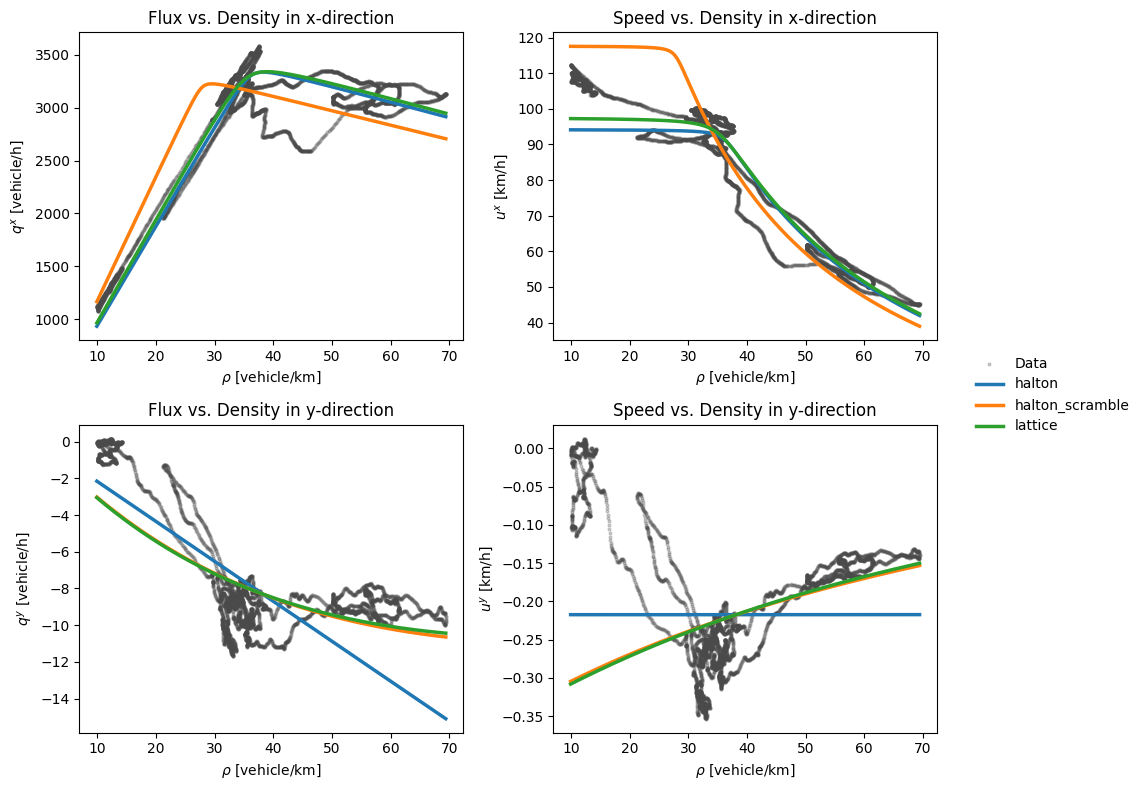

In [9]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw = 2.5
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for method, res in QMCCBO_results.items():
    ax[0,0].plot(rho_plot, res["qx_fit"], linewidth=lw, label=method)
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for method, res in QMCCBO_results.items():
    ax[0,1].plot(rho_plot, res["ux_fit"], linewidth=lw, label=method)
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for method, res in QMCCBO_results.items():
    ax[1,0].plot(rho_plot, res["qy_fit"], linewidth=lw, label=method)
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for method, res in QMCCBO_results.items():
    ax[1,1].plot(rho_plot, res["uy_fit"], linewidth=lw, label=method)
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

handles, labels = ax[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.88, 0.5), frameon=False, fontsize=10,)

plt.tight_layout(rect=[0, 0, 0.87, 1])
plt.savefig("images/fundamental_diagrams_QMCCBO_init_offramp.png", dpi=300, bbox_inches="tight")
plt.show()

### Comparison Nelder-Mead and L-BFGS-B with different starting values

Nelder-Mead (Simplex)

In [42]:
# initial simplex
function_value = 1e-6

initial_simplices = [
    np.array([
        [100,   1, -20],
        [300,   1, -20],
        [100,-200, -20],
        [100,   1, 400],
    ]),
    np.array([
        [0, 0, 0],
        [100, 0, 0],
        [0, 100, 0],
        [0, 0, 100],
    ]),
    np.array([
        [-85, -85, -85],
        [115, -85, -85],
        [-85, 115, -85],
        [-85, -85, 115],
    ]),
]
simplex_results = {}

# Model prediction and qualitiy measures for each starting point
for i, initial_simplex in enumerate(initial_simplices):

    x0 = initial_simplex
    
    # Model prediction
    result_x = minimize(objective_x_numpy, x0=initial_simplex[0], method="Nelder-Mead", options={"initial_simplex": initial_simplex, "fatol": function_value,  "maxfev": 2048,  "maxiter": 1300})
    result_y = minimize(objective_y_numpy, x0=initial_simplex[0], method="Nelder-Mead", options={"initial_simplex": initial_simplex, "fatol": function_value,  "maxfev": 2048,  "maxiter": 1300})
    alpha_x, lambda_x, p_x = result_x.x
    alpha_y, lambda_y, p_y = result_y.x

    # Fitted curves
    qx_fit = qx_model_numpy(rho_plot, alpha_x, lambda_x, p_x)
    qy_fit = qy_model_numpy(rho_plot, alpha_y, lambda_y, p_y)
    ux_fit = qx_fit / np.maximum(rho_plot, 1e-6)
    uy_fit = qy_fit / np.maximum(rho_plot, 1e-6)

    # Errors
    qx_fit_data = qx_model_numpy(rho_data, alpha_x, lambda_x, p_x)
    qy_fit_data = qy_model_numpy(rho_data, alpha_y, lambda_y, p_y)
    err_x = (np.linalg.norm(qx_data - qx_fit_data) / np.linalg.norm(qx_data))
    err_y = (np.linalg.norm(qy_data - qy_fit_data) / np.linalg.norm(qy_data))

    key = tuple(tuple(row) for row in x0)
    simplex_results[key] = {
        "params_x": (alpha_x, lambda_x, p_x),
        "params_y": (alpha_y, lambda_y, p_y),
        "qx_fit": qx_fit,
        "qy_fit": qy_fit,  
        "ux_fit": ux_fit,
        "uy_fit": uy_fit,
        "err_x": err_x,
        "err_y": err_y,
    }

In [43]:
rows = []

for x0, res in simplex_results.items():

    alpha_x, lambda_x, p_x = res["params_x"]
    alpha_y, lambda_y, p_y = res["params_y"]

    rows.append({
    "x0": str(x0),
    "αˣ": alpha_x,
    "λˣ": lambda_x,
    "pˣ": p_x,
    "error qˣ": res["err_x"],
    "αʸ": alpha_y,
    "λʸ": lambda_y,
    "pʸ": p_y,
    "error qʸ": res["err_y"],
    }) 

df = pd.DataFrame(rows)
df

,x0,αˣ,λˣ,pˣ,error qˣ,αʸ,λʸ,pʸ,error qʸ
0,"((100, 1, -20), (300, 1, -20), (100, -200, -20...",240.491247,64.649128,0.12546,0.05593,-739.554905,-24.056191,-0.340141,0.238459
1,"((0, 0, 0), (100, 0, 0), (0, 100, 0), (0, 0, 1...",240.491234,-64.649131,0.12546,0.05593,0.000000,0.000000,0.000000,1.000000
2,"((-85, -85, -85), (115, -85, -85), (-85, 115, ...",240.491222,64.649134,0.12546,0.05593,-0.072734,-549.796143,0.142220,0.186388


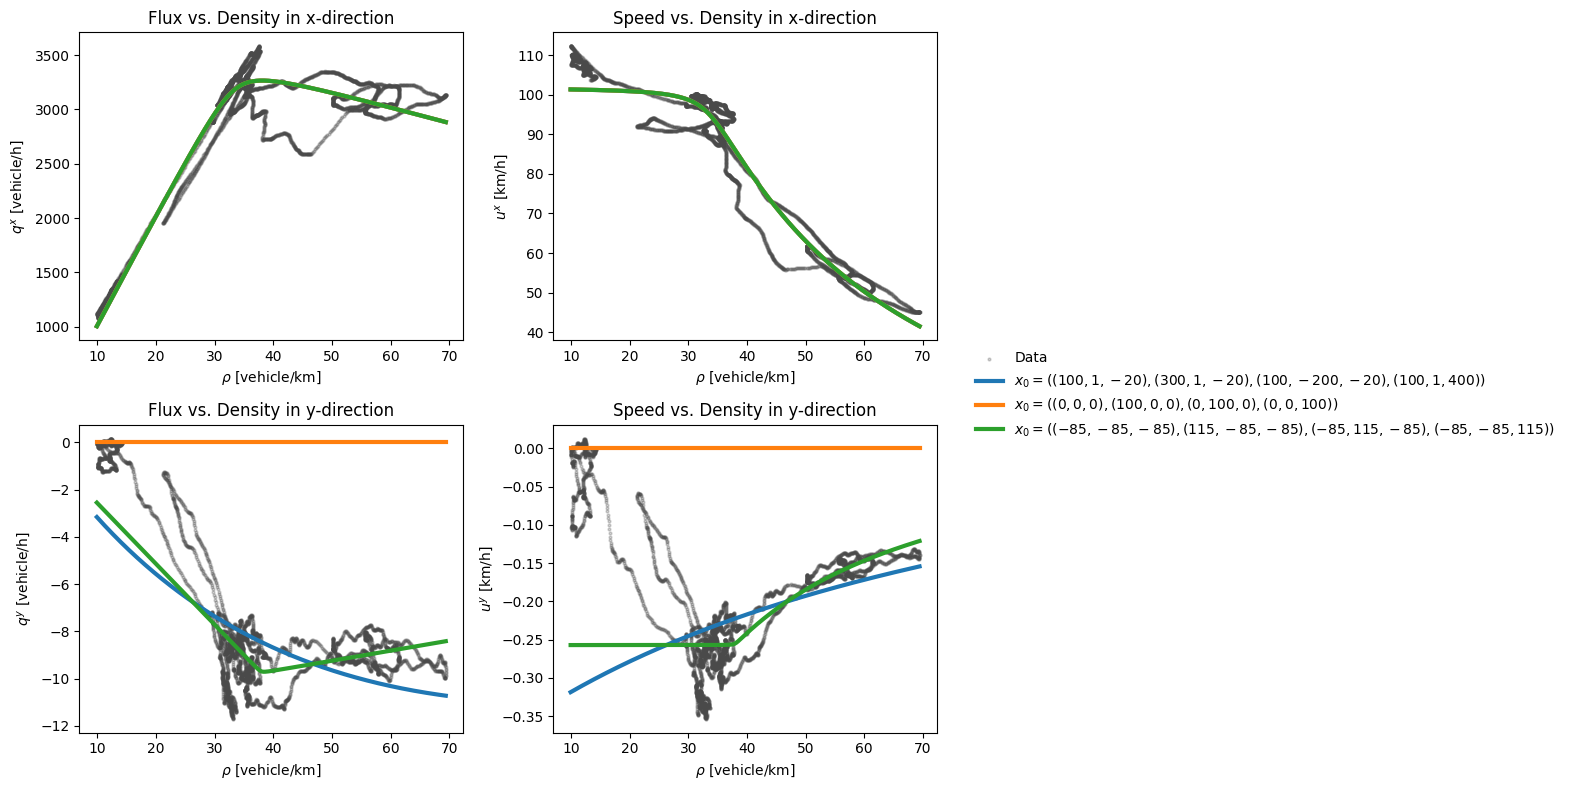

In [44]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw = 3
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in simplex_results.items():
    ax[0,0].plot(rho_plot, res["qx_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in simplex_results.items():
    ax[0,1].plot(rho_plot, res["ux_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in simplex_results.items():
    ax[1,0].plot(rho_plot, res["qy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in simplex_results.items():
    ax[1,1].plot(rho_plot, res["uy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

handles, labels = ax[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.88, 0.5), frameon=False, fontsize=10,)

plt.tight_layout(rect=[0, 0, 0.87, 1])
plt.savefig("images/fundamental_diagrams_simplex_init_offramp.png", dpi=300, bbox_inches="tight")
plt.show()

L-BFGS-B

In [45]:
initial_values = [
    [0, -350, 0],
    [-10, -10, -10],
    [100, 100, 100],
]

lbfgs_results = {}

# Model prediction and qualitiy measures for each starting point
for x0 in initial_values:

    x0 = np.asarray(x0)

    # Model prediction
    result_x = minimize(objective_x_numpy, x0=x0, method="L-BFGS-B", bounds=[(-500,500), (-500,500), (-500,500)], options={"maxiter": 400, "maxfun": 2048, "ftol": function_value, "maxcor": 10})
    result_y = minimize(objective_y_numpy, x0=x0, method="L-BFGS-B", bounds=[(-500,500), (-500,500), (-500,500)], options={"maxiter": 400, "maxfun": 2048, "ftol": function_value, "maxcor": 10})
    alpha_x, lambda_x, p_x = result_x.x
    alpha_y, lambda_y, p_y = result_y.x

    # Fitted curves
    qx_fit = qx_model_numpy(rho_plot, alpha_x, lambda_x, p_x)
    qy_fit = qy_model_numpy(rho_plot, alpha_y, lambda_y, p_y)
    ux_fit = qx_fit / np.maximum(rho_plot, 1e-6)
    uy_fit = qy_fit / np.maximum(rho_plot, 1e-6)

    # Errors
    qx_fit_data = qx_model_numpy(rho_data, alpha_x, lambda_x, p_x)
    qy_fit_data = qy_model_numpy(rho_data, alpha_y, lambda_y, p_y)
    err_x = (np.linalg.norm(qx_data - qx_fit_data) / np.linalg.norm(qx_data))
    err_y = (np.linalg.norm(qy_data - qy_fit_data) / np.linalg.norm(qy_data))

    lbfgs_results[tuple(x0)] = {
        "params_x": (alpha_x, lambda_x, p_x),
        "params_y": (alpha_y, lambda_y, p_y),
        "qx_fit": qx_fit,
        "qy_fit": qy_fit,
        "ux_fit": ux_fit,
        "uy_fit": uy_fit,
        "err_x": err_x,
        "err_y": err_y,
    }

In [46]:
rows = []

for x0, res in lbfgs_results.items():

    alpha_x, lambda_x, p_x = res["params_x"]
    alpha_y, lambda_y, p_y = res["params_y"]

    rows.append({
    "x0": str(x0),
    "αˣ": alpha_x,
    "λˣ": lambda_x,
    "pˣ": p_x,
    "error qˣ": res["err_x"],
    "αʸ": alpha_y,
    "λʸ": lambda_y,
    "pʸ": p_y,
    "error qʸ": res["err_y"],
    }) 

df = pd.DataFrame(rows)
df

,x0,αˣ,λˣ,pˣ,error qˣ,αʸ,λʸ,pʸ,error qʸ
0,"(0, -350, 0)",500.000000,-350.000000,0.009086,0.27394,-500.000000,-349.999922,-0.052123,0.305851
1,"(-10, -10, -10)",-10.000000,-500.000000,-500.000000,1.00000,-13.722728,-5.601380,0.079345,0.228733
2,"(100, 100, 100)",45.108455,330.465886,0.128345,0.05747,100.000000,100.000001,100.000001,1.000000


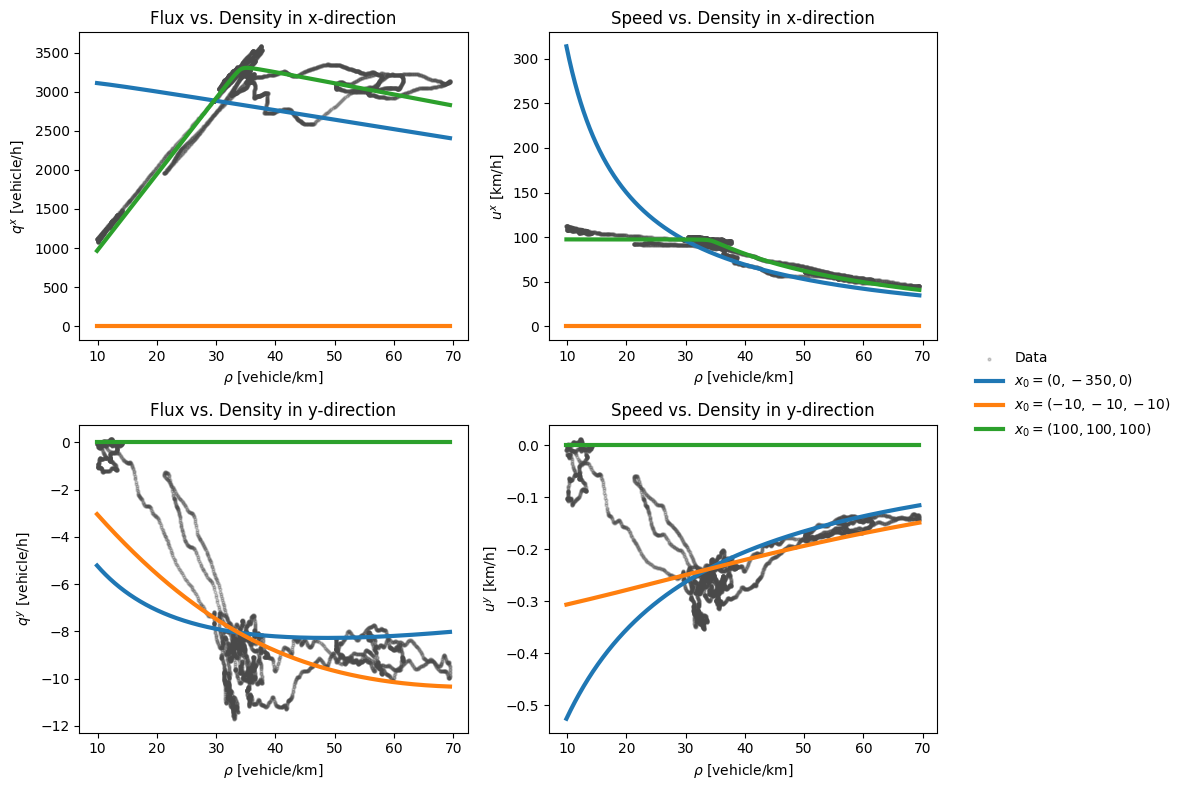

In [47]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw = 3
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in lbfgs_results.items():
    ax[0,0].plot(rho_plot, res["qx_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in lbfgs_results.items():
    ax[0,1].plot(rho_plot, res["ux_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in lbfgs_results.items():
    ax[1,0].plot(rho_plot, res["qy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in lbfgs_results.items():
    ax[1,1].plot(rho_plot, res["uy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

handles, labels = ax[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.88, 0.5), frameon=False, fontsize=10,)

plt.tight_layout(rect=[0, 0, 0.87, 1])
plt.savefig("images/fundamental_diagrams_lbfgs_init_offramp.png", dpi=300, bbox_inches="tight")
plt.show()

### Comparison Differential Evolution and CBO for different starting configuration (different runs)

Differential Evolution

In [48]:
num_repeats = 3
de_results = {}

# Model prediction and qualitiy measures for each starting point
for i in range(num_repeats):
    
    # Model prediction
    result_x = differential_evolution(objective_x_numpy, bounds=[(-500,500), (-500,500), (-500,500)], tol=function_value, maxiter=44, init='random', updating='deferred', polish=False)
    result_y = differential_evolution(objective_y_numpy, bounds=[(-500,500), (-500,500), (-500,500)], tol=function_value, maxiter=44, init='random', updating='deferred', polish=False)
    alpha_x, lambda_x, p_x = result_x.x
    alpha_y, lambda_y, p_y = result_y.x

    # Fitted curves
    qx_fit = qx_model_numpy(rho_plot, alpha_x, lambda_x, p_x)
    qy_fit = qy_model_numpy(rho_plot, alpha_y, lambda_y, p_y)
    ux_fit = qx_fit / np.maximum(rho_plot, 1e-6)
    uy_fit = qy_fit / np.maximum(rho_plot, 1e-6)

    # Errors
    qx_fit_data = qx_model_numpy(rho_data, alpha_x, lambda_x, p_x)
    qy_fit_data = qy_model_numpy(rho_data, alpha_y, lambda_y, p_y)
    err_x = (np.linalg.norm(qx_data - qx_fit_data) / np.linalg.norm(qx_data))
    err_y = (np.linalg.norm(qy_data - qy_fit_data) / np.linalg.norm(qy_data))

    de_results[i] = {
        "params_x": (alpha_x, lambda_x, p_x),
        "params_y": (alpha_y, lambda_y, p_y),
        "qx_fit": qx_fit,
        "qy_fit": qy_fit,
        "ux_fit": ux_fit,
        "uy_fit": uy_fit,
        "err_x": err_x,
        "err_y": err_y,
    }

In [49]:
rows = []

for i, res in de_results.items():

    alpha_x, lambda_x, p_x = res["params_x"]
    alpha_y, lambda_y, p_y = res["params_y"]

    rows.append({
    "αˣ": alpha_x,
    "λˣ": lambda_x,
    "pˣ": p_x,
    "error qˣ": res["err_x"],
    "αʸ": alpha_y,
    "λʸ": lambda_y,
    "pʸ": p_y,
    "error qʸ": res["err_y"],
    }) 

df = pd.DataFrame(rows)
df

,αˣ,λˣ,pˣ,error qˣ,αʸ,λʸ,pʸ,error qʸ
0,256.499517,304.201427,-21.246312,1.000000,-392.225363,-472.931140,25.743362,1.000000
1,251.199733,-61.730134,0.126074,0.056006,-282.136081,-10.391319,-0.309509,0.238480
2,473.285472,-229.043605,-3.833086,0.999999,-25.367592,4.668424,0.005271,0.235573


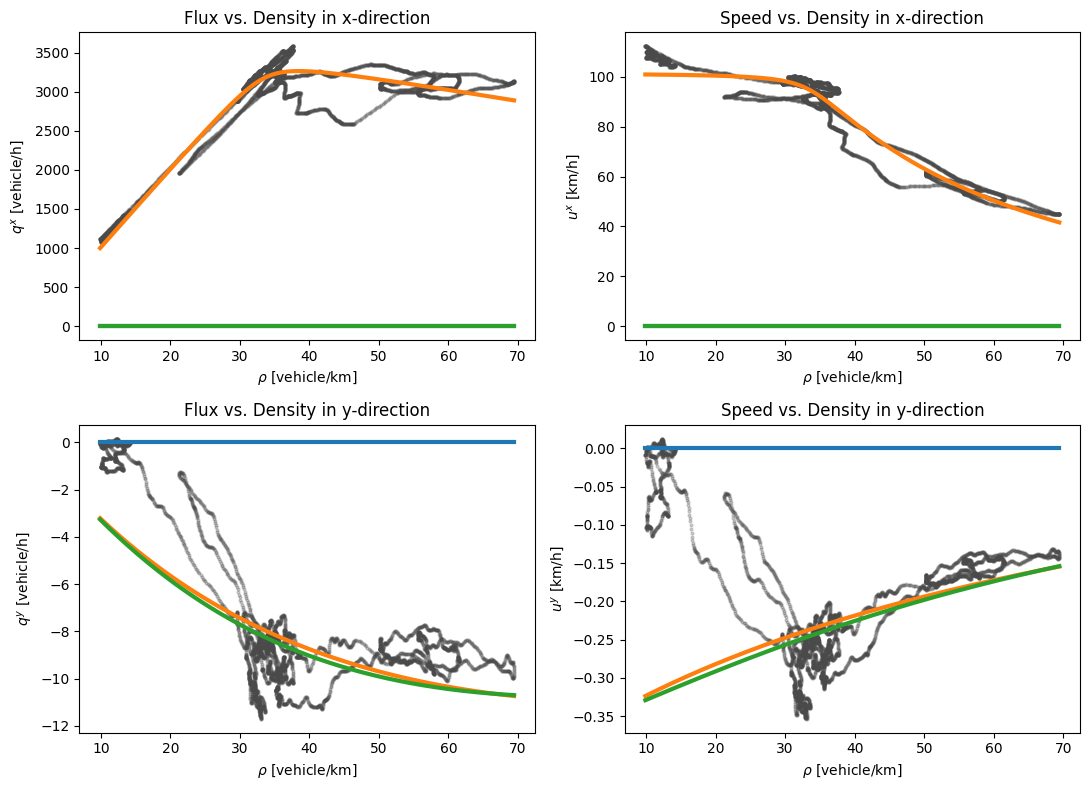

In [50]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw = 3
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in de_results.items():
    ax[0,0].plot(rho_plot, res["qx_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in de_results.items():
    ax[0,1].plot(rho_plot, res["ux_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in de_results.items():
    ax[1,0].plot(rho_plot, res["qy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in de_results.items():
    ax[1,1].plot(rho_plot, res["uy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_de_init_offramp.png", dpi=300, bbox_inches="tight")
plt.show()

CBO

In [51]:
# set standard input for (QMC)CBO
dimensionality = 3  # dimension of the problem
n_particles = 11  # number of agents 2^n_particles
dt = 0.05  # step size of discretization
l = 1  # lambda (drift paramter)
sigma = 1
alpha = 100  # alpha (consensus weight)
n_particles_batches = 1  # batch size of each batch
epochs = 100  # number of iteration od SDE solution scheme (M)
batch_size = None
time_horizon = None
initial_distribution = Uniform(-500,500)  # initial distribution function
SDE_method = 'Euler_Maruyama'  # SDE solution scheme
anisotropic = False  # anisotropic CBO

In [55]:
num_repeats = 3
CBO_results = {}

# Model prediction and qualitiy measures for each starting point
for i in range(num_repeats):
    
    # Model prediction
    result_x = CBO.minimize(
        objective_x_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
    result_y = CBO.minimize(
        objective_y_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
    alpha_x, lambda_x, p_x = np.clip(result_x.numpy(), -500, 500)
    alpha_y, lambda_y, p_y = np.clip(result_y.numpy(), -500, 500)

    # Fitted curves
    qx_fit = qx_model_numpy(rho_plot, alpha_x, lambda_x, p_x)
    qy_fit = qy_model_numpy(rho_plot, alpha_y, lambda_y, p_y)
    ux_fit = qx_fit / np.maximum(rho_plot, 1e-6)
    uy_fit = qy_fit / np.maximum(rho_plot, 1e-6)

    # Errors
    qx_fit_data = qx_model_numpy(rho_data, alpha_x, lambda_x, p_x)
    qy_fit_data = qy_model_numpy(rho_data, alpha_y, lambda_y, p_y)
    err_x = (np.linalg.norm(qx_data - qx_fit_data) / np.linalg.norm(qx_data))
    err_y = (np.linalg.norm(qy_data - qy_fit_data) / np.linalg.norm(qy_data))

    CBO_results[i] = {
        "params_x": (alpha_x, lambda_x, p_x),
        "params_y": (alpha_y, lambda_y, p_y),
        "qx_fit": qx_fit,
        "qy_fit": qy_fit,
        "ux_fit": ux_fit,
        "uy_fit": uy_fit,
        "err_x": err_x,
        "err_y": err_y,
    }

In [56]:
rows = []

for i, res in CBO_results.items():

    alpha_x, lambda_x, p_x = res["params_x"]
    alpha_y, lambda_y, p_y = res["params_y"]

    rows.append({
    "αˣ": alpha_x,
    "λˣ": lambda_x,
    "pˣ": p_x,
    "error qˣ": res["err_x"],
    "αʸ": alpha_y,
    "λʸ": lambda_y,
    "pʸ": p_y,
    "error qʸ": res["err_y"],
    }) 

df = pd.DataFrame(rows)
df

,αˣ,λˣ,pˣ,error qˣ,αʸ,λʸ,pʸ,error qʸ
0,149.302292,97.353195,0.130205,0.065297,-238.864426,219.838577,1.009420,0.298282
1,40.041355,385.341644,0.126515,0.063958,-500.000000,20.847958,-0.337167,0.313261
2,-500.000000,500.000000,-500.000000,1.000000,-102.723801,-500.000000,1.001087,0.321152


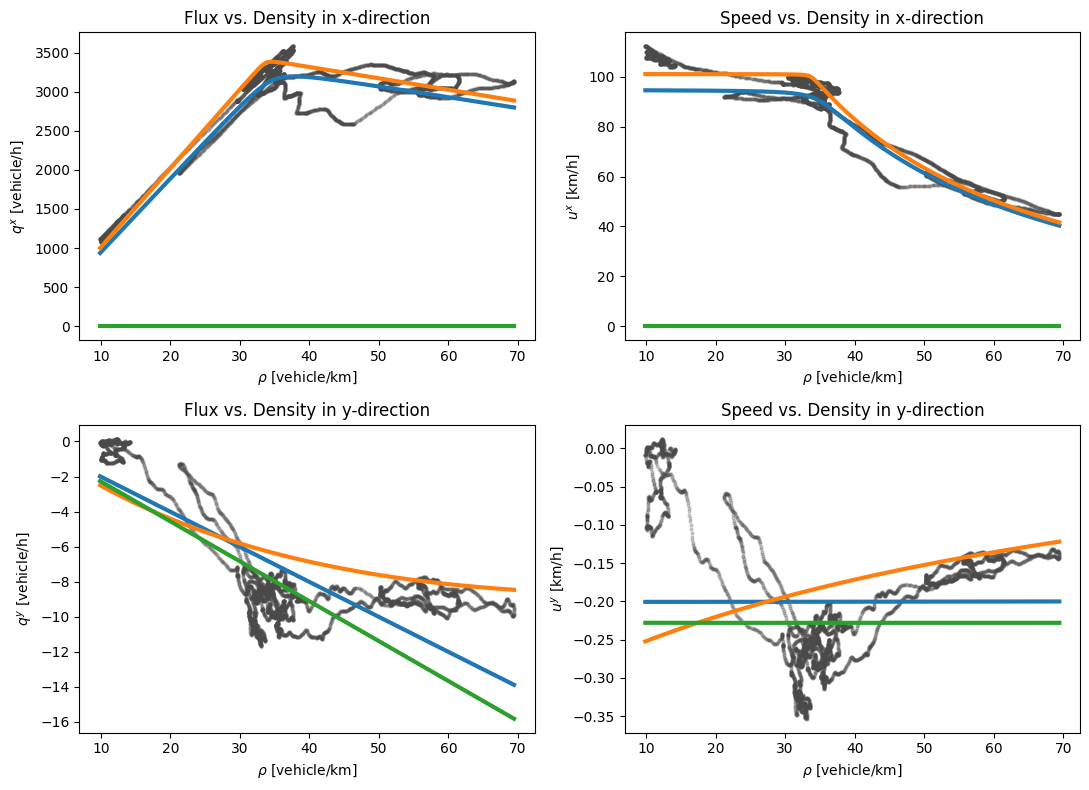

In [57]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw = 3
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in CBO_results.items():
    ax[0,0].plot(rho_plot, res["qx_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in CBO_results.items():
    ax[0,1].plot(rho_plot, res["ux_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in CBO_results.items():
    ax[1,0].plot(rho_plot, res["qy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
for x0, res in CBO_results.items():
    ax[1,1].plot(rho_plot, res["uy_fit"], linewidth=lw, label=rf"$x_0={x0}$")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_cbo_init_offramp.png", dpi=300, bbox_inches="tight")
plt.show()